# Fase 6 — Incerteza do forecast e risco da observação da demanda

**Somente outputs derivados de train. Eval fechado. ETS e forecasts preservados.**

Perfis em 25/06/2024, disponíveis após essa data. Labels da Fase 3 são usados para diagnóstico retrospectivo e não podem ser reutilizados dentro dos folds anteriores como informação já conhecida. Não há reconstrução de demanda, lost sales, intervalo probabilístico ou fórmula de safety stock.

Lógica em src; relatório `docs/forecast_uncertainty_and_risk_report.md`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.demand_risk_report import load_outputs
from src.reporting.demand_risk_plots import PLOTS, save_figure
data = load_outputs(root)
assert data['summary']['source_split'] == 'train'
assert data['summary']['n_fits_performed'] == 0
assert data['summary']['available_from'] == '2024-06-26'
display(data['calibration'].loc[data['calibration'].level.eq('global')])

,level,n_forecasts,n_series,n_products,n_folds,actual_total,forecast_total,mae,rmse,wape,...,backtest_actual_share,series_share,abc_class,xyz_class,stockout_exposure,censoring_risk_flag,demand_observation_risk_cell,adequate_descriptive_support,as_of,analysis_view
41,global,1400000,50000,865,4,1518029.667,1.485072e+06,0.390632,0.672312,0.36026,...,1.0,1.0,NaN,NaN,NaN,None,None,True,2024-06-25,post_backtest_as_of_train_end


## 01. Distribuição de bias

Cada série agrega 28 dias. Bias negativo não comprova ruptura ou demanda perdida.

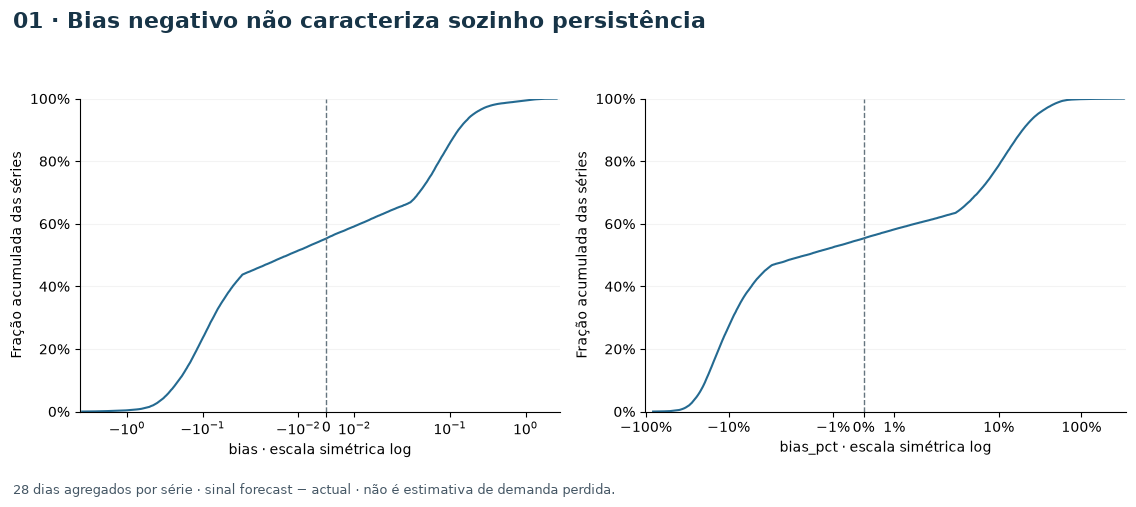

In [2]:
fig = PLOTS[0](data)
save_figure(fig, 1, root)
display(fig)
plt.close(fig)

## 02. Incerteza empírica

Desvio amostral, RMSE, p90 e p95 absolutos. Caudas por série têm amostra pequena; não são intervalos probabilísticos.

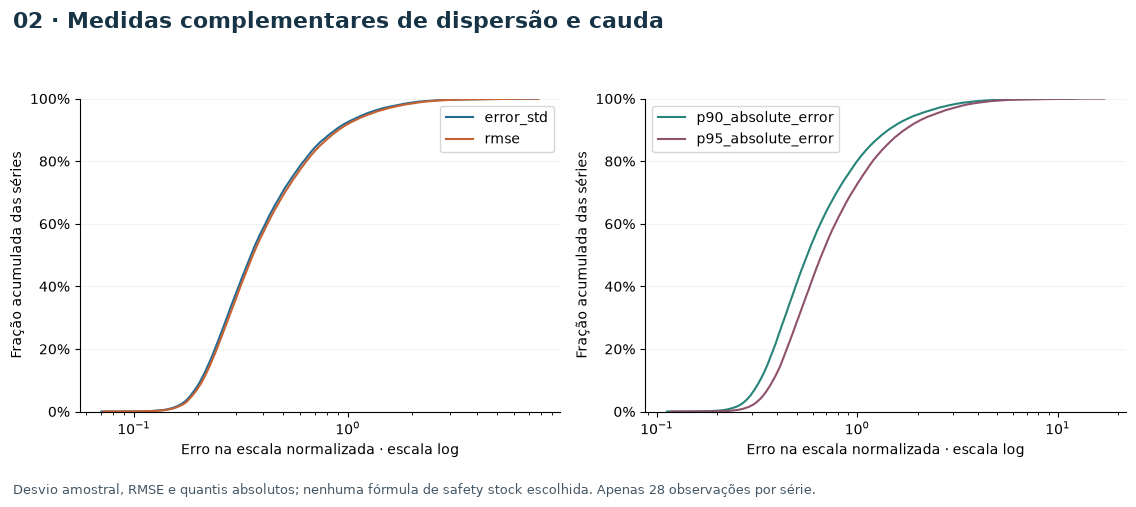

In [3]:
fig = PLOTS[1](data)
save_figure(fig, 2, root)
display(fig)
plt.close(fig)

## 03. Persistência e frequência

Regra oficial: bias consolidado<0 e pelo menos três folds negativos. Frequência de dias subprevistos é outra dimensão.

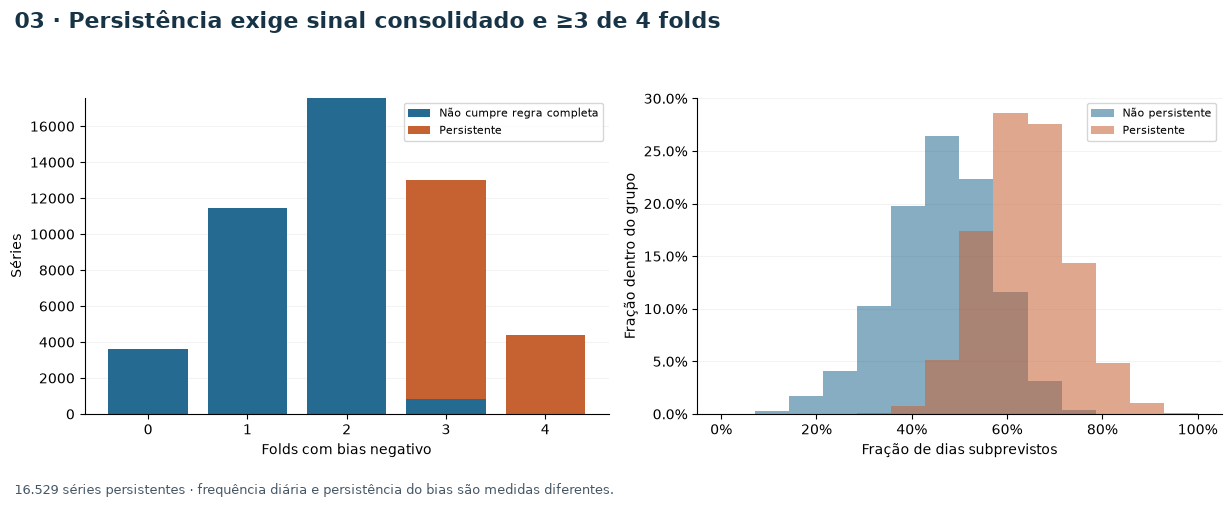

,negative_bias_fold_count,n_series,persistent_series,train_sales
0,0,3587,0,388182.104
1,1,11432,0,971308.501
2,2,17593,0,1534537.448
3,3,13020,12161,1201469.775
4,4,4368,4368,398162.959


,minimum_negative_folds,n_series,series_share,double_risk_series,train_sales_share
0,2,26322,0.52644,1544,0.538490
1,3,16529,0.33058,1028,0.340216
2,4,4368,0.08736,281,0.088605


In [4]:
fig = PLOTS[2](data)
save_figure(fig, 3, root)
display(fig)
plt.close(fig)
display(data['persistence_distribution'])
display(data['persistence_sensitivity'])

## 04. Exposição à ruptura

Comparação descritiva pelas classes conhecidas em 25/06. Escala explica por que maior erro absoluto pode coexistir com menor WAPE.

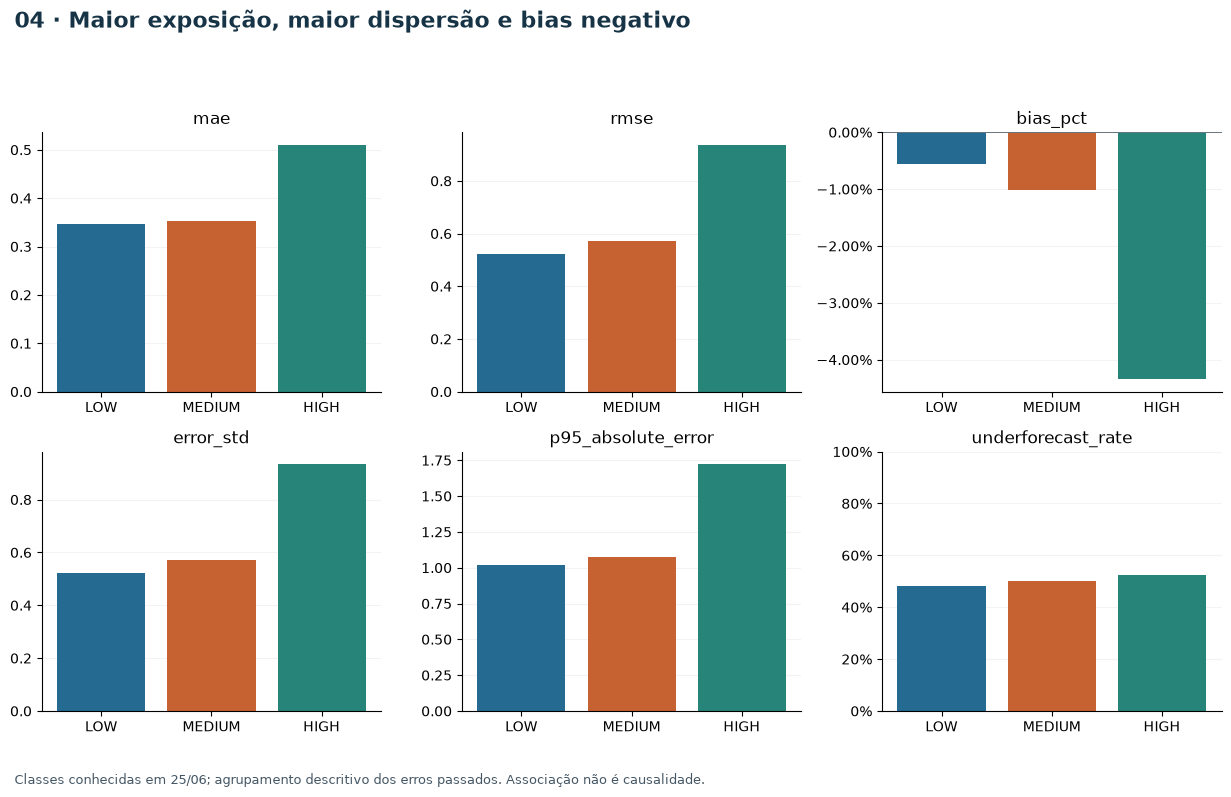

In [5]:
fig = PLOTS[3](data)
save_figure(fig, 4, root)
display(fig)
plt.close(fig)

## 05. Possível censura

Flag preservada da Fase 3. Erros maiores e bias mais negativo não significam necessariamente mais dias subprevistos.

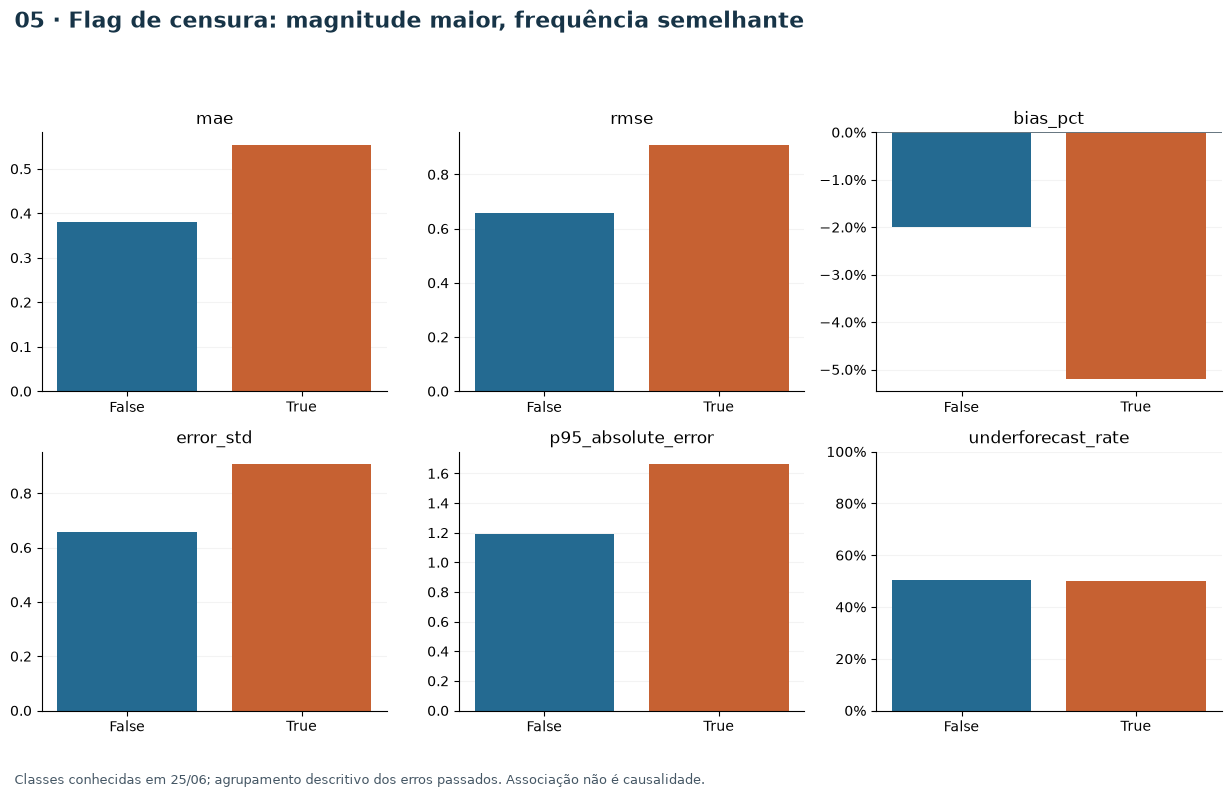

In [6]:
fig = PLOTS[4](data)
save_figure(fig, 5, root)
display(fig)
plt.close(fig)

## 06. Matriz de dois sinais

Nenhum score. NEITHER é ausência dos dois sinais específicos, não ausência de todo risco.

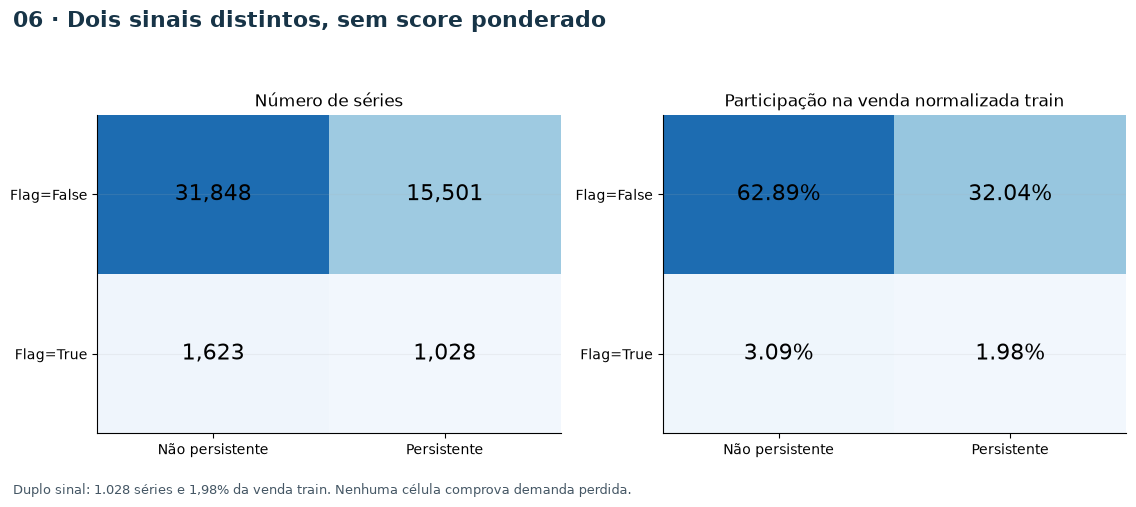

,group,metric,global_p75_threshold,n_series,n_at_or_above_p75,share_at_or_above_p75
0,ALL,error_std,0.550570,50000,12500,0.250000
1,ALL,rmse,0.567010,50000,12500,0.250000
2,ALL,p90_absolute_error,0.883176,50000,12500,0.250000
3,ALL,p95_absolute_error,1.055403,50000,12500,0.250000
4,CENSORING_AND_UNDERFORECAST,error_std,0.550570,1028,518,0.503891
5,CENSORING_AND_UNDERFORECAST,rmse,0.567010,1028,529,0.514591
6,CENSORING_AND_UNDERFORECAST,p90_absolute_error,0.883176,1028,543,0.528210
7,CENSORING_AND_UNDERFORECAST,p95_absolute_error,1.055403,1028,536,0.521401
8,CENSORING_ONLY,error_std,0.550570,1623,794,0.489217
9,CENSORING_ONLY,rmse,0.567010,1623,792,0.487985


In [7]:
fig = PLOTS[5](data)
save_figure(fig, 6, root)
display(fig)
plt.close(fig)
display(data['high_uncertainty_diagnostics'])

## 07. Matriz por ABC

A/B com duplo sinal são recortes para investigação posterior, sem recomendação de compra. Venda normalizada não é receita.

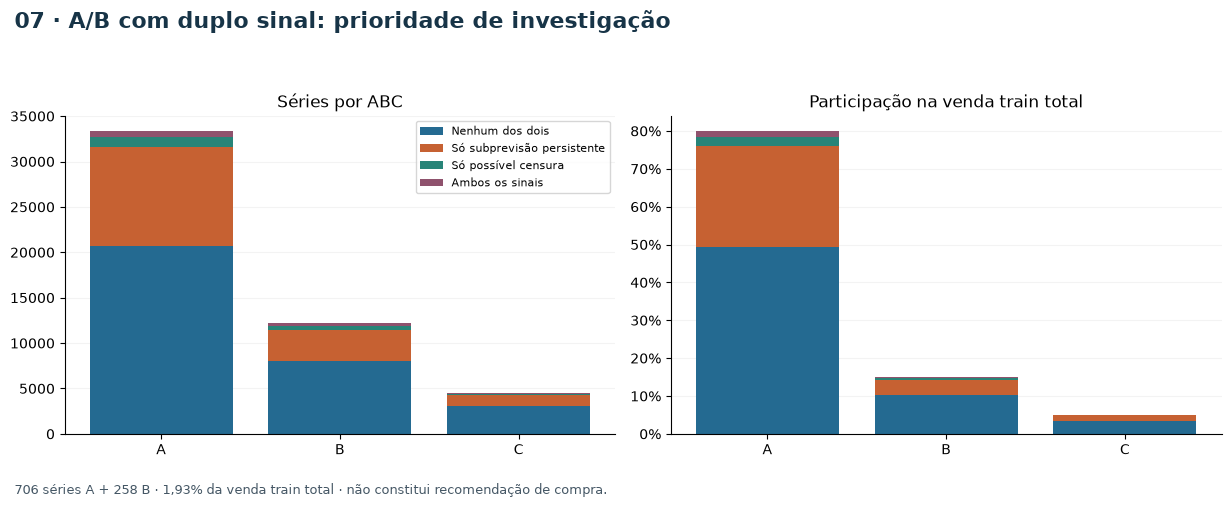

In [8]:
fig = PLOTS[6](data)
save_figure(fig, 7, root)
display(fig)
plt.close(fig)

## 08. Incerteza por XYZ

Quantis/desvios calculados das observações agrupadas. As classes finais não são tratadas como conhecidas em origens anteriores.

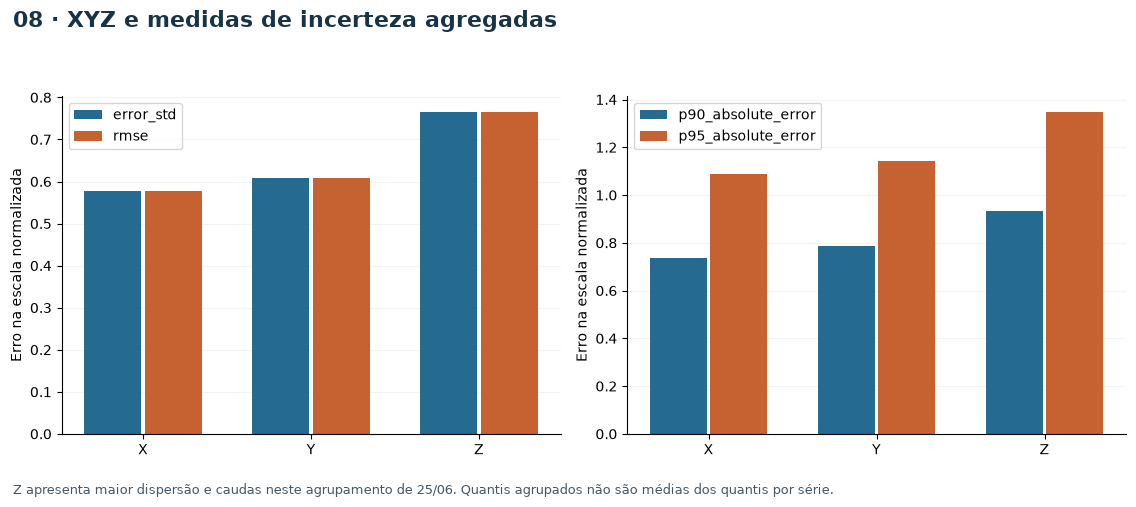

In [9]:
fig = PLOTS[7](data)
save_figure(fig, 8, root)
display(fig)
plt.close(fig)

## 09. Exemplos reproduzíveis

Quatro exemplos A próximos à mediana de error_std de cada célula; máximos de desvio/taxa em A; menor MAE entre LOW. Desempates por IDs. Linhas verticais separam os folds.

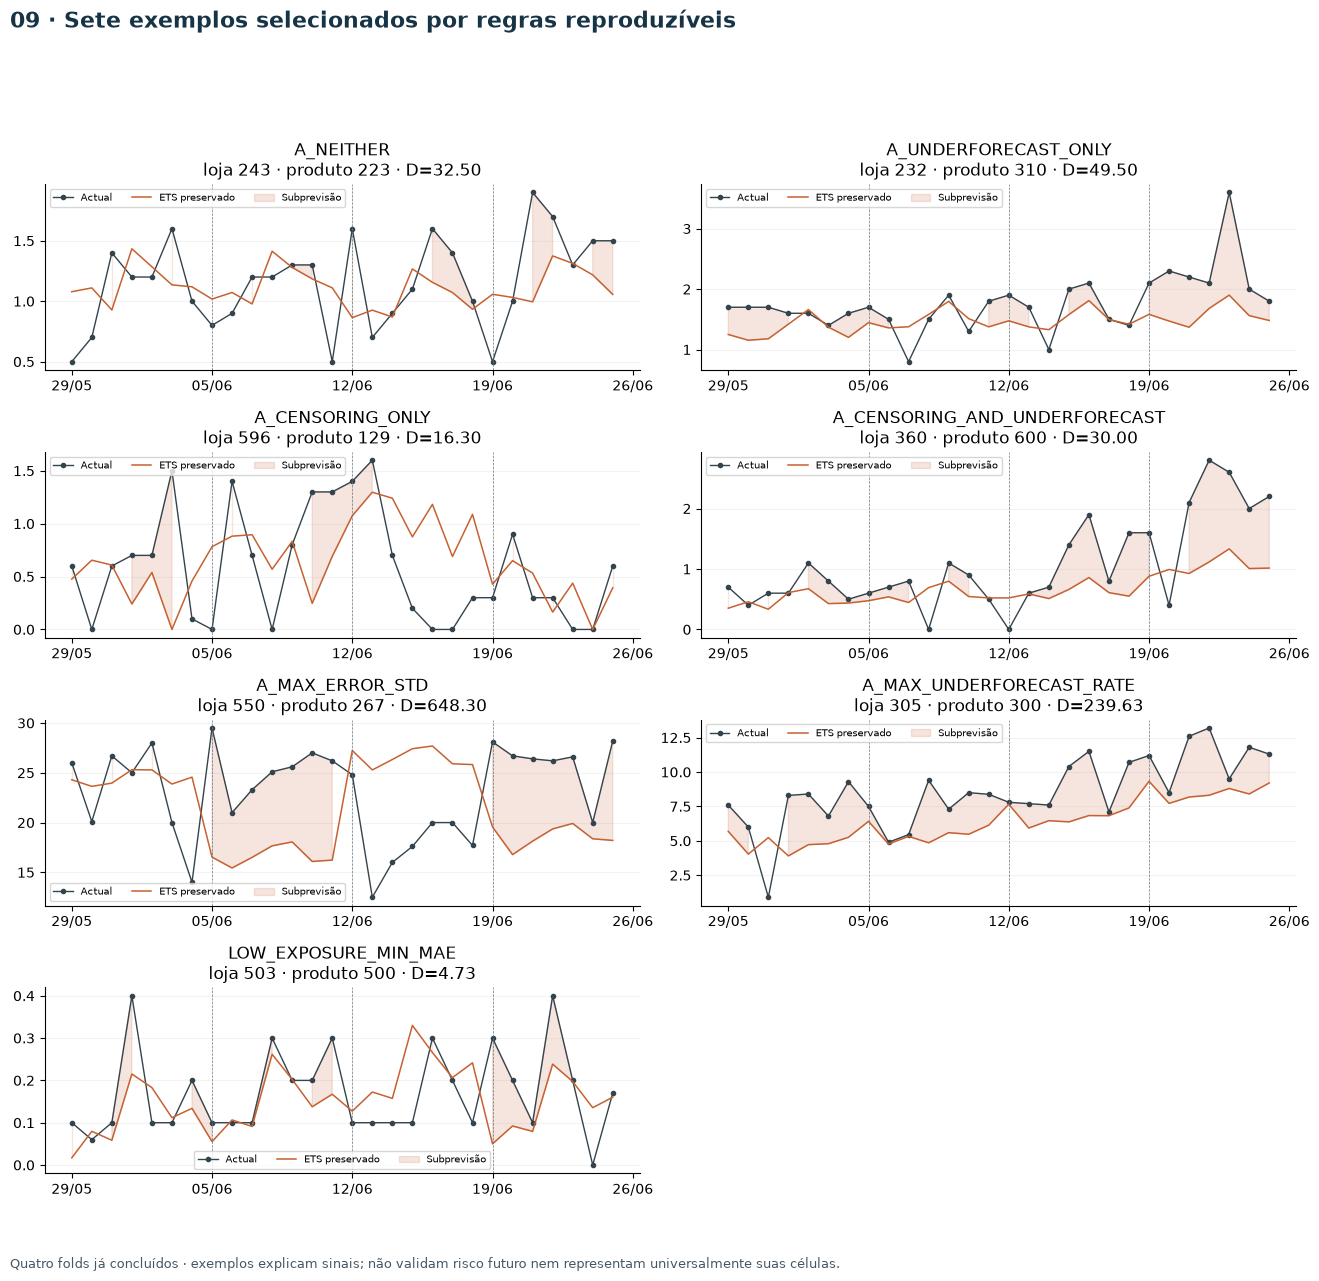

In [10]:
fig = PLOTS[8](data)
save_figure(fig, 9, root)
display(fig)
plt.close(fig)

## 10. Robustez

Omitir fold 4 inverte o bias global. Remover p1/p99 reduz bastante RMSE. São análises separadas; todos os erros permanecem nos resultados oficiais.

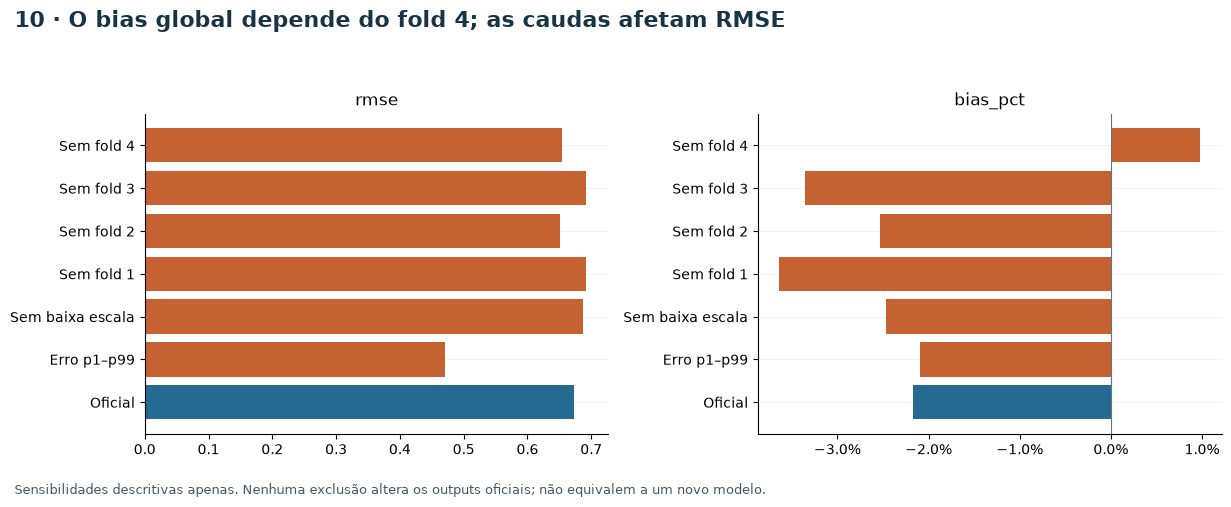

,omitted_fold,official_persistent_series,still_negative_consolidated,negative_in_all_three_remaining,negative_in_at_least_two_remaining
0,1,16529,15672,8259,16529
1,2,16529,15436,7458,16529
2,3,16529,15646,7785,16529
3,4,16529,14974,6131,16529


,group,n_series,actual_total,actual_share,persistent_series,median_wape,p95_wape,median_error_std
0,at_or_below_p05,2501,21041.048,0.013861,230,0.611292,1.676367,0.222359
1,above_p05,47499,1496988.619,0.986139,16299,0.371900,0.729466,0.361823


In [11]:
fig = PLOTS[9](data)
save_figure(fig, 10, root)
display(fig)
plt.close(fig)
display(data['persistence_retention'])
display(data['low_scale_diagnostics'])

## Interpretação e limites

16.529 séries são persistentes (33,058%); 1.028 combinam persistência e possível censura. A + duplo sinal reúne 706 séries e 1,641% da venda normalizada train. 518 séries com duplo sinal têm error_std no quartil superior global, incluindo 398 A.

A flag de censura está associada a maior magnitude de erro e bias mais negativo; a frequência de subprevisão é semelhante (50,09% com flag; 50,23% sem). Não há inferência causal. A composição da matriz usa o próprio erro na definição da persistência; separação de bias não é validação independente de poder preditivo.

O bias global depende do último fold, mas 90,59% dos persistentes mantêm bias negativo sem ele. 28 observações limitam p90/p95; as séries compartilham loja/produto/calendário. Apenas diagnóstico: nenhuma escolha de safety stock, correção de forecast ou abertura do holdout.